In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
 #       print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_score, recall_score, f1_score, accuracy_score
import seaborn as sns
from transformers import ViTModel
from sklearn.model_selection import KFold
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Hyperparameters
image_size = (224, 224)
batch_size = 16
epochs = 30
learning_rate = 0.0001
gamma = 0.5

dataset_path = "/kaggle/input/monkeypoxskinimagedataset/Monkeypox Skin Image Dataset"

# Define transformation with augmentation
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

def filter_dataset():
    dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
    class_to_idx = dataset.class_to_idx
    monkeypox_idx = class_to_idx["Monkeypox"]
    for i in range(len(dataset.samples)):
        img_path, label = dataset.samples[i]
        dataset.samples[i] = (img_path, 0 if label == monkeypox_idx else 1)
    return dataset

dataset = filter_dataset()

class BroadAttention(nn.Module):
    def __init__(self, hidden_size, num_layers=4):
        super(BroadAttention, self).__init__()
        self.attention = nn.MultiheadAttention(embed_dim=hidden_size, num_heads=8)
        self.pool = nn.AdaptiveAvgPool1d(1)

    def forward(self, queries, keys, values):
        queries = torch.cat(queries, dim=1)
        keys = torch.cat(keys, dim=1)
        values = torch.cat(values, dim=1)
        attention_output, _ = self.attention(queries, keys, values)
        pooled_output = self.pool(attention_output.permute(0, 2, 1)).squeeze(-1)
        return pooled_output

class B2VITNet(nn.Module):
    def __init__(self, vit_model_name, num_classes, gamma=0.5):
        super(B2VITNet, self).__init__()
        self.vit = ViTModel.from_pretrained(vit_model_name, output_attentions=True)
        self.hidden_size = self.vit.config.hidden_size
        self.gamma = gamma
        self.broad_attention_1 = BroadAttention(hidden_size=self.hidden_size)
        self.refinement_attention = nn.MultiheadAttention(embed_dim=self.hidden_size, num_heads=8)
        self.classifier = nn.Sequential(
            nn.Linear(self.hidden_size, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, pixel_values):
        outputs = self.vit(pixel_values, output_hidden_states=True)
        hidden_states = outputs.hidden_states
        deep_features = hidden_states[-1][:, 0, :]
        queries = [layer[:, 0, :].unsqueeze(1) for layer in hidden_states]
        broad_features_1 = self.broad_attention_1(queries, queries, queries)
        broad_features_1 = broad_features_1.unsqueeze(1).permute(1, 0, 2)
        refined_features, _ = self.refinement_attention(broad_features_1, broad_features_1, broad_features_1)
        refined_features = refined_features.permute(1, 0, 2).squeeze(1)
        combined_features = deep_features + self.gamma * refined_features
        logits = self.classifier(combined_features)
        return logits

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs):
    for epoch in range(epochs):
        model.train()
        train_loss, val_loss = 0.0, 0.0
        train_preds, train_targets, val_preds, val_targets = [], [], [], []
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)
            train_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            train_targets.extend(labels.cpu().numpy())
        
        train_loss /= len(train_loader.dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_precision = precision_score(train_targets, train_preds, average='weighted')
        train_recall = recall_score(train_targets, train_preds, average='weighted')
        train_f1 = f1_score(train_targets, train_preds, average='weighted')

        model.eval()
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_loss /= len(val_loader.dataset)
        val_acc = accuracy_score(val_targets, val_preds)
        val_precision = precision_score(val_targets, val_preds, average='weighted')
        val_recall = recall_score(val_targets, val_preds, average='weighted')
        val_f1 = f1_score(val_targets, val_preds, average='weighted')
        
        print(f"Epoch {epoch+1}/{epochs}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Prec: {train_precision:.4f}, Recall: {train_recall:.4f}, F1: {train_f1:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Prec: {val_precision:.4f}, Recall: {val_recall:.4f}, F1: {val_f1:.4f}")

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []
for fold, (train_indices, val_indices) in enumerate(kf.split(dataset)):
    train_subset, val_subset = Subset(dataset, train_indices), Subset(dataset, val_indices)
    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
    model = B2VITNet("google/vit-base-patch16-224-in21k", num_classes=2, gamma=gamma).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    train_model(model, train_loader, val_loader, criterion, optimizer, epochs)
    print(f"Fold {fold + 1} complete!")


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

`ViTSdpaAttention` is used but `torch.nn.functional.scaled_dot_product_attention` does not support `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


Epoch 1/30: Train Loss: 0.4057, Train Acc: 0.8409, Prec: 0.8400, Recall: 0.8409, F1: 0.8404, Val Loss: 0.1704, Val Acc: 0.9221, Prec: 0.9227, Recall: 0.9221, F1: 0.9222
Epoch 2/30: Train Loss: 0.1941, Train Acc: 0.9237, Prec: 0.9235, Recall: 0.9237, F1: 0.9236, Val Loss: 0.0920, Val Acc: 0.9740, Prec: 0.9740, Recall: 0.9740, F1: 0.9740
Epoch 3/30: Train Loss: 0.1333, Train Acc: 0.9562, Prec: 0.9561, Recall: 0.9562, F1: 0.9561, Val Loss: 0.1713, Val Acc: 0.9286, Prec: 0.9311, Recall: 0.9286, F1: 0.9289
Epoch 4/30: Train Loss: 0.0512, Train Acc: 0.9756, Prec: 0.9758, Recall: 0.9756, F1: 0.9757, Val Loss: 0.1061, Val Acc: 0.9675, Prec: 0.9675, Recall: 0.9675, F1: 0.9675
Epoch 5/30: Train Loss: 0.0860, Train Acc: 0.9659, Prec: 0.9659, Recall: 0.9659, F1: 0.9658, Val Loss: 0.1498, Val Acc: 0.9545, Prec: 0.9590, Recall: 0.9545, F1: 0.9548
Epoch 6/30: Train Loss: 0.1234, Train Acc: 0.9545, Prec: 0.9548, Recall: 0.9545, F1: 0.9546, Val Loss: 0.1419, Val Acc: 0.9675, Prec: 0.9675, Recall: 0.967

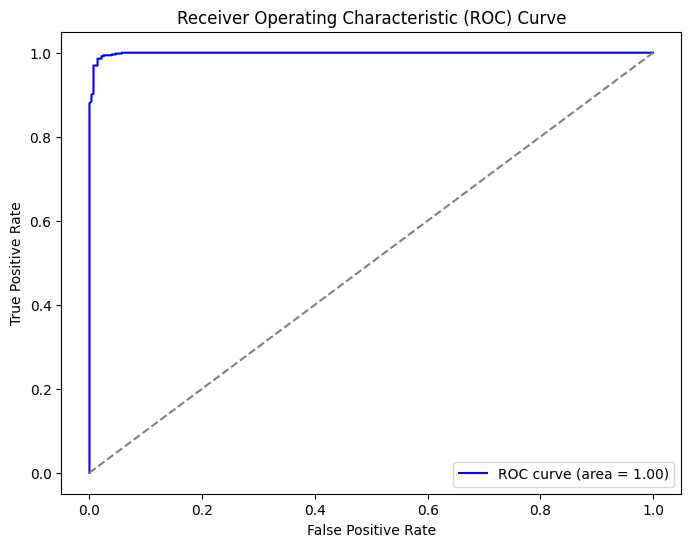

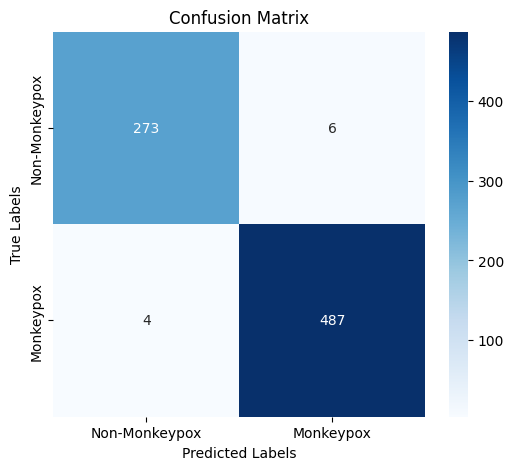

In [3]:

import torch.nn.functional as F
import itertools

y_true_all, y_pred_all = [], []

for fold, (train_indices, val_indices) in enumerate(kf.split(dataset)):
    train_subset, val_subset = Subset(dataset, train_indices), Subset(dataset, val_indices)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
    
    model.eval()
    fold_y_true, fold_y_pred = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probabilities = F.softmax(outputs, dim=1)[:, 1].cpu().numpy()
            fold_y_true.extend(labels.cpu().numpy())
            fold_y_pred.extend(probabilities)
    
    y_true_all.extend(fold_y_true)
    y_pred_all.extend(fold_y_pred)

# Compute ROC Curve and AUC
fpr, tpr, _ = roc_curve(y_true_all, y_pred_all)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()

# Compute and plot confusion matrix
threshold = 0.5  # Classify based on probability threshold
y_pred_binary = [1 if pred >= threshold else 0 for pred in y_pred_all]
conf_matrix = confusion_matrix(y_true_all, y_pred_binary)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Monkeypox', 'Monkeypox'], yticklabels=['Non-Monkeypox', 'Monkeypox'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

